# HealthAware — Decision Tree Model (Deliverable 2)

**Course:** ICS 3202 — Artificial Intelligence  
**Project:** HealthAware — Diabetes-related Risk Classification  
**Dataset:** CDC BRFSS 2015 Diabetes Health Indicators

## Notebook purpose

This notebook documents the machine-learning workflow required for Deliverable 2:

1. Load and inspect the dataset.
2. Explain the data-quality checks and exploratory findings.
3. Prepare the predictors and target, then create a stratified training/test split.
4. Train and validate classification models using the same five-fold cross-validation process.
5. Compare model performance, select a candidate model, and evaluate it on the test set.
6. Save the selected model for later integration.

**Target variable:** `Diabetes_012`

- `0` — No diabetes
- `1` — Prediabetes
- `2` — Diabetes

**Project scope:** HealthAware is an experimental screening and awareness assistant. The model does not diagnose diabetes. The dataset is from the United States, so its results cannot automatically be generalised to Kenya.

## 1. Load the dataset

The dataset contains health and lifestyle indicators. The target column contains the category that the model will learn to predict.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = "data/diabetes_012_health_indicators_BRFSS2015.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


## 2. Data quality checks

Check the dataset dimensions, missing values, exact duplicate rows, data types and target labels.

These checks describe the data as received. In this workflow, duplicate rows are counted but not automatically deleted. Removing repeated survey records without understanding their origin could change the class distribution. The dataset also contains repeated predictor combinations with more than one target label, which should be treated as a data limitation rather than silently corrected.

In [2]:
print("Rows and columns:", df.shape)
print("\nMissing values:", df.isna().sum().sum())
print("Exact duplicate rows:", df.duplicated().sum())

print("\nData types:")
display(df.dtypes.to_frame("Data type"))

print("\nTarget values:")
print(sorted(df["Diabetes_012"].unique()))

Rows and columns: (253680, 22)

Missing values: 0
Exact duplicate rows: 23899

Data types:


,Data type
Diabetes_012,float64
HighBP,float64
HighChol,float64
CholCheck,float64
BMI,float64
Smoker,float64
Stroke,float64
HeartDiseaseorAttack,float64
PhysActivity,float64
Fruits,float64



Target values:
[np.float64(0.0), np.float64(1.0), np.float64(2.0)]


In [3]:
# Check whether identical predictor values are associated with multiple target labels.
feature_columns = df.columns.drop("Diabetes_012")

target_variation = (
    df.groupby(list(feature_columns))["Diabetes_012"]
      .nunique()
)

print(
    "Distinct predictor combinations associated with multiple target labels:",
    int((target_variation > 1).sum())
)

Distinct predictor combinations associated with multiple target labels: 1834


## 3. Exploratory Data Analysis (EDA)

EDA is used to understand the dataset before modelling. The following analyses provide four important observations: target-class imbalance, BMI distribution, BMI by target category, and high-blood-pressure prevalence by target category.

### 3.1 Target-class distribution

,Count,Percentage
Diabetes_012,,
0.0,213703,84.24
1.0,4631,1.83
2.0,35346,13.93


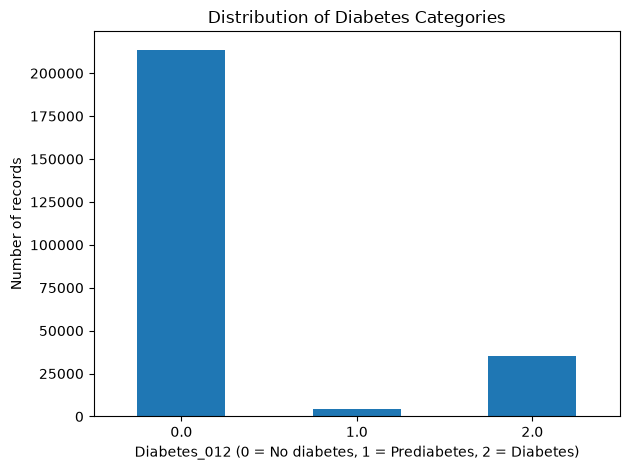

In [4]:
target_counts = df["Diabetes_012"].value_counts().sort_index()
target_percentages = df["Diabetes_012"].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages.round(2)
})
display(target_summary)

target_counts.plot(kind="bar", rot=0)
plt.title("Distribution of Diabetes Categories")
plt.xlabel("Diabetes_012 (0 = No diabetes, 1 = Prediabetes, 2 = Diabetes)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

**Observation 1 — Class imbalance:** The no-diabetes category is the majority class, while prediabetes is a small minority class. This matters because a model can achieve high accuracy by favouring the majority class while failing to identify prediabetes cases.

### 3.2 BMI distribution and summary

count    253680.000000
mean         28.382364
std           6.608694
min          12.000000
25%          24.000000
50%          27.000000
75%          31.000000
max          98.000000
Name: BMI, dtype: float64


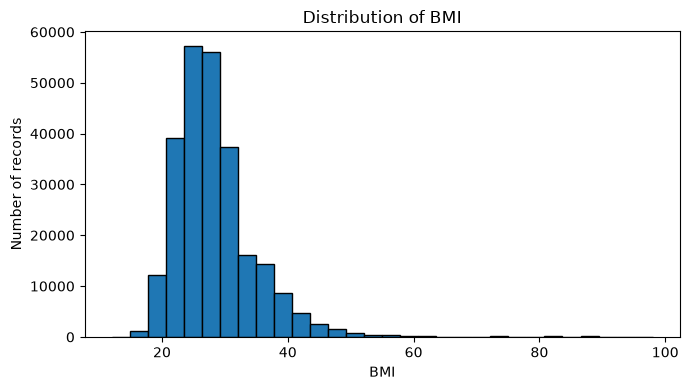

In [5]:
print(df["BMI"].describe())

plt.figure(figsize=(7, 4))
plt.hist(df["BMI"], bins=30, edgecolor="black")
plt.title("Distribution of BMI")
plt.xlabel("BMI")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

**Observation 2 — BMI distribution:** The summary statistics and histogram show the spread of BMI values and whether extreme values are present. Report the mean, median, minimum and maximum from the output. Do not infer that BMI causes a diabetes category from this chart.

### 3.3 BMI across the three target categories

,count,mean,median,min,max
Diabetes_012,,,,,
0.0,213703,27.742521,27.0,12.0,98.0
1.0,4631,30.724466,30.0,13.0,96.0
2.0,35346,31.944011,31.0,13.0,98.0


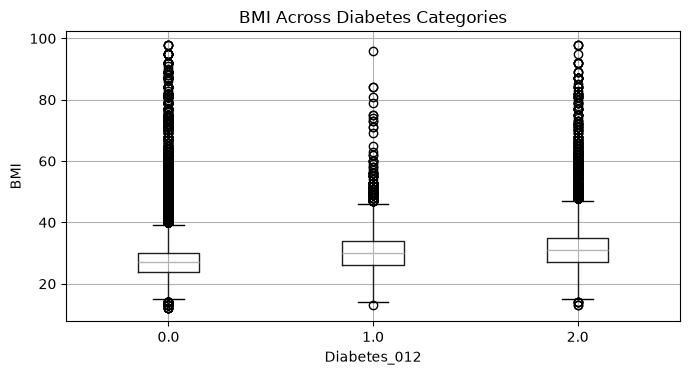

In [6]:
bmi_by_class = df.groupby("Diabetes_012")["BMI"].agg(
    ["count", "mean", "median", "min", "max"]
)
display(bmi_by_class)

df.boxplot(column="BMI", by="Diabetes_012", figsize=(7, 4))
plt.title("BMI Across Diabetes Categories")
plt.suptitle("")
plt.xlabel("Diabetes_012")
plt.ylabel("BMI")
plt.tight_layout()
plt.show()

**Observation 3 — BMI by category:** Compare the median BMI values and the boxplots across the three target categories. In the earlier exploration, the medians were 27 for no diabetes, 30 for prediabetes and 31 for diabetes. These are descriptive differences, not evidence of causation.

### 3.4 High blood pressure across target categories

,Percentage with HighBP
Diabetes_012,
0.0,37.113190
1.0,62.902181
2.0,75.267357


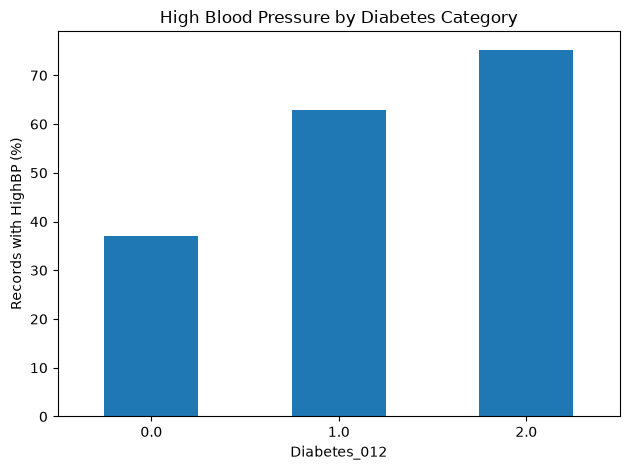

In [7]:
high_bp_by_class = df.groupby("Diabetes_012")["HighBP"].mean() * 100
display(high_bp_by_class.rename("Percentage with HighBP").to_frame())

high_bp_by_class.plot(kind="bar", rot=0)
plt.title("High Blood Pressure by Diabetes Category")
plt.xlabel("Diabetes_012")
plt.ylabel("Records with HighBP (%)")
plt.tight_layout()
plt.show()

**Observation 4 — High blood pressure:** In the earlier exploration, the proportion with `HighBP = 1` was 37.11% in the no-diabetes category, 62.90% in prediabetes and 75.27% in diabetes. This shows an association in this dataset; it does not establish that high blood pressure causes diabetes.

## 4. Prepare features and target

The target column is separated from the input features:

- `X` contains the 21 health and lifestyle predictors.
- `y` contains the target category, `Diabetes_012`.

The data are split into 80% training and 20% testing. Stratification preserves the class proportions in both subsets. The test set is kept separate from model fitting.

In [8]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Diabetes_012"])
y = df["Diabetes_012"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target distribution:")
display(y_train.value_counts().sort_index().to_frame("Count"))
print("\nTesting target distribution:")
display(y_test.value_counts().sort_index().to_frame("Count"))

Training features: (202944, 21)
Testing features: (50736, 21)

Training target distribution:


,Count
Diabetes_012,
0.0,170962
1.0,3705
2.0,28277



Testing target distribution:


,Count
Diabetes_012,
0.0,42741
1.0,926
2.0,7069


## 5. Classification approach and evaluation plan

This is **supervised multiclass classification**: the training data contain known labels, and the model predicts one of three categories.

A Decision Tree is used as the base algorithm because it learns a sequence of feature-based decision rules and is relatively easy to explain. Since the target classes are imbalanced, accuracy alone is not sufficient.

The models are compared using the same **stratified five-fold cross-validation** process on the training data. Each fold preserves approximate class proportions. Macro F1 gives each class equal weight, making it useful when one class is much smaller than the others.

The experiments below compare:
1. Decision Tree baseline.
2. SMOTENC Decision Tree.
3. SMOTENC Random Forest.
4. Balanced Random Forest.
5. Class-weighted Decision Tree.

SMOTENC is placed inside a pipeline so that synthetic samples are created only from each fold's training portion. This avoids resampling the validation fold.

In [16]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

# Categorical predictors used by SMOTENC.
categorical_features = [
    "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
    "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost",
    "GenHlth", "DiffWalk", "Sex", "Age", "Education", "Income"
]

categorical_indices = [
    X_train.columns.get_loc(column)
    for column in categorical_features
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "macro_f1": "f1_macro",
    "accuracy": "accuracy"
}

### 5.1 Define the models

In [10]:
models = {
    "Decision Tree baseline": DecisionTreeClassifier(
        random_state=42
    ),

    "SMOTENC Decision Tree": ImbPipeline(steps=[
        ("smotenc", SMOTENC(
            categorical_features=categorical_indices,
            random_state=42,
            k_neighbors=5
        )),
        ("classifier", DecisionTreeClassifier(
            random_state=42
        ))
    ]),

    "SMOTENC Random Forest": ImbPipeline(steps=[
        ("smotenc", SMOTENC(
            categorical_features=categorical_indices,
            random_state=42,
            k_neighbors=5
        )),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Balanced Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Class-weighted Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=8,
        random_state=42
    )
}

### 5.2 Run the same five-fold cross-validation for every model

For each model, calculate Macro F1 and accuracy on the five validation folds. Then generate out-of-fold predictions to calculate precision and recall for the prediabetes class. Out-of-fold means each training observation is predicted by a model that did not train on that observation.

In [11]:
cv_results = []
oof_predictions = {}

for model_name, estimator in models.items():
    print("Evaluating:", model_name)

    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    predictions = cross_val_predict(
        estimator,
        X_train,
        y_train,
        cv=cv,
        n_jobs=-1
    )

    oof_predictions[model_name] = predictions

    cv_results.append({
        "Model": model_name,
        "Mean Macro F1": scores["test_macro_f1"].mean(),
        "Macro F1 SD": scores["test_macro_f1"].std(),
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Prediabetes Precision": precision_score(
            y_train, predictions, labels=[1],
            average="macro", zero_division=0
        ),
        "Prediabetes Recall": recall_score(
            y_train, predictions, labels=[1],
            average="macro", zero_division=0
        ),
        "Prediabetes F1": f1_score(
            y_train, predictions, labels=[1],
            average="macro", zero_division=0
        )
    })

cv_comparison = pd.DataFrame(cv_results).sort_values(
    "Mean Macro F1", ascending=False
).reset_index(drop=True)

display(cv_comparison.round(4))

Evaluating: Decision Tree baseline
Evaluating: SMOTENC Decision Tree
Evaluating: SMOTENC Random Forest
Evaluating: Balanced Random Forest
Evaluating: Class-weighted Decision Tree


,Model,Mean Macro F1,Macro F1 SD,Mean Accuracy,Prediabetes Precision,Prediabetes Recall,Prediabetes F1
0,Balanced Random Forest,0.4414,0.0024,0.7917,0.0198,0.0051,0.0081
1,SMOTENC Random Forest,0.4404,0.0042,0.7969,0.0291,0.0227,0.0255
2,SMOTENC Decision Tree,0.4021,0.0039,0.7397,0.0268,0.0648,0.0379
3,Class-weighted Decision Tree,0.3989,0.0070,0.5818,0.0256,0.3250,0.0475
4,Decision Tree baseline,0.3987,0.0036,0.7666,0.0244,0.0318,0.0276


### 5.3 Examine class-level results

Macro F1 summarises performance across classes, but the class-level report shows how well each model identifies no diabetes, prediabetes and diabetes separately.

In [12]:
for model_name, predictions in oof_predictions.items():
    print("\n", "=" * 70)
    print(model_name)
    print(classification_report(
        y_train,
        predictions,
        labels=[0, 1, 2],
        target_names=["No diabetes", "Prediabetes", "Diabetes"],
        digits=4,
        zero_division=0
    ))


Decision Tree baseline
              precision    recall  f1-score   support

 No diabetes     0.8750    0.8572    0.8660    170962
 Prediabetes     0.0244    0.0318    0.0276      3705
    Diabetes     0.2910    0.3152    0.3026     28277

    accuracy                         0.7666    202944
   macro avg     0.3968    0.4014    0.3987    202944
weighted avg     0.7781    0.7666    0.7722    202944


SMOTENC Decision Tree
              precision    recall  f1-score   support

 No diabetes     0.8840    0.8164    0.8489    170962
 Prediabetes     0.0268    0.0648    0.0379      3705
    Diabetes     0.2851    0.3639    0.3197     28277

    accuracy                         0.7397    202944
   macro avg     0.3986    0.4150    0.4022    202944
weighted avg     0.7849    0.7397    0.7603    202944


SMOTENC Random Forest
              precision    recall  f1-score   support

 No diabetes     0.8958    0.8703    0.8829    170962
 Prediabetes     0.0291    0.0227    0.0255      3705
    D

## 6. Model comparison and selection

The Random Forest experiments achieved the strongest overall Macro F1 in the earlier runs. However, their prediabetes recall was very low. The class-weighted Decision Tree achieved substantially higher prediabetes recall, which is why it was selected as the candidate for HealthAware.

This is a deliberate trade-off: the selected model detects more prediabetes cases, but its precision is low and it produces many false positives. The selection does not mean it is the best model for every metric.

The table below is generated from the current notebook run. Use these same-process cross-validation results when explaining the model comparison. Do not mix a held-out test score from one experiment with cross-validation scores from another as if they were directly comparable.

In [13]:
# Focused comparison of the two main candidates.
display(
    cv_comparison[
        cv_comparison["Model"].isin([
            "Balanced Random Forest",
            "Class-weighted Decision Tree"
        ])
    ].round(4)
)

,Model,Mean Macro F1,Macro F1 SD,Mean Accuracy,Prediabetes Precision,Prediabetes Recall,Prediabetes F1
0,Balanced Random Forest,0.4414,0.0024,0.7917,0.0198,0.0051,0.0081
3,Class-weighted Decision Tree,0.3989,0.0070,0.5818,0.0256,0.3250,0.0475


## 7. Train and save the selected model

The selected configuration is a class-weighted Decision Tree with maximum depth 8. It is fitted on the complete training set and saved with Joblib.

The model file expects the same 21 input columns, in the same order and with the same value encoding used during training.

In [14]:
import joblib
from pathlib import Path

final_model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=8,
    random_state=42
)

final_model.fit(X_train, y_train)

Path("models").mkdir(exist_ok=True)
model_path = Path("models/healthaware_diabetes_model.joblib")

joblib.dump(final_model, model_path)

print("Saved model:", model_path)
print("Training rows:", X_train.shape[0])
print("Number of features:", X_train.shape[1])
print("Model classes:", final_model.classes_)

Saved model: models\healthaware_diabetes_model.joblib
Training rows: 202944
Number of features: 21
Model classes: [0. 1. 2.]


## 8. Final evaluation on the test set

The test set is used here to show how the selected model performs on records excluded from its final training fit. However, this test set was also used in earlier experiments during model development. It is therefore not a completely untouched final holdout, and the results should be reported with that limitation.

The most important issue to discuss is the balance between prediabetes recall and precision.

Test accuracy: 0.6032

Classification report:
              precision    recall  f1-score   support

 No diabetes     0.9528    0.6087    0.7428     42741
 Prediabetes     0.0266    0.2927    0.0487       926
    Diabetes     0.3266    0.6111    0.4257      7069

    accuracy                         0.6032     50736
   macro avg     0.4353    0.5041    0.4057     50736
weighted avg     0.8487    0.6032    0.6860     50736


Confusion matrix:
[[26015  8239  8487]
 [  234   271   421]
 [ 1054  1695  4320]]


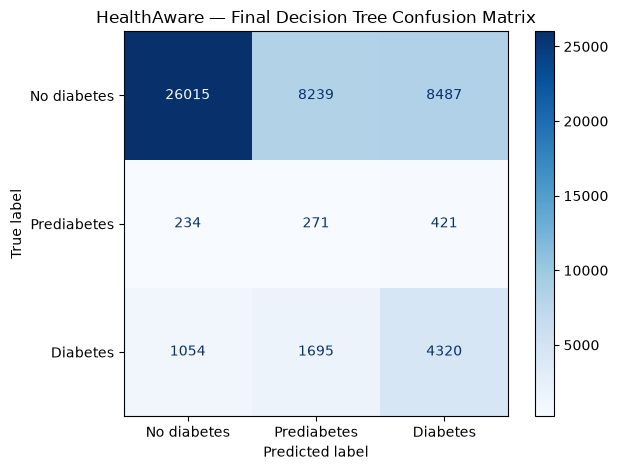

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

y_test_pred = final_model.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("\nClassification report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1, 2],
    target_names=["No diabetes", "Prediabetes", "Diabetes"],
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1, 2])
print("\nConfusion matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No diabetes", "Prediabetes", "Diabetes"]
).plot(cmap="Blues", values_format="d")

plt.title("HealthAware — Final Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

### 8.1 Interpretation of the final test results

In the previous run, the selected model achieved:

- Accuracy: 60.32%
- Macro F1: 40.57%
- Prediabetes precision: 2.66%
- Prediabetes recall: 29.27%

It correctly identified 271 of the 926 actual prediabetes records. However, it predicted 10,205 records as prediabetes, and only 271 were correct. This is a substantial false-positive problem.

The model is an experimental classification candidate for a screening and awareness application. It is not a clinical diagnostic tool. Independent validation and improved precision are required before practical use.

## 9. Conclusion and limitations

The notebook demonstrates the required workflow: data inspection, EDA, data preparation, supervised multiclass classification, cross-validation, comparison of alternative methods, final model training and test evaluation.

The class-weighted Decision Tree was selected because it provided higher prediabetes recall than the other main experiments. Its low precision is a major limitation and must be stated clearly.

### Limitations

1. **Class imbalance:** Prediabetes represents only a small proportion of the dataset.
2. **False positives:** The selected model flags many records as prediabetes incorrectly.
3. **Dataset population:** BRFSS 2015 is U.S. survey data; results cannot automatically be generalised to Kenya.
4. **Not diagnostic:** The model does not replace laboratory testing or professional medical assessment.
5. **Test-set reuse:** The test set was examined during earlier experimentation, so it is not a fully independent final holdout.
6. **Survey data limitations:** Repeated or conflicting predictor profiles may occur in the source dataset.

### Final conclusion

Class weighting improved the model's ability to identify the minority prediabetes class, but this improvement came with a high false-positive rate. The selected model is retained as an experimental candidate for HealthAware, with further validation and precision improvement required before deployment.



## Outlier Detection and Investigation

Outlier detection is performed to identify numerical observations
that are unusually far from the rest of the data.

The Interquartile Range (IQR) method is used to investigate
possible outliers in BMI, MentHlth and PhysHlth.

Categorical and ordinal features are checked separately for
invalid category values because their numerical codes represent
categories rather than continuous measurements.

Identified outliers will be investigated before any records
are removed or modified.

In [17]:
# Numerical features to investigate
numerical_features = ["BMI", "MentHlth", "PhysHlth"]

# Calculate IQR-based outlier boundaries
outlier_results = []

for column in numerical_features:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": len(outliers) / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,BMI,24.0,31.0,7.0,13.5,41.5,9847,3.88
1,MentHlth,0.0,2.0,2.0,-3.0,5.0,36208,14.27
2,PhysHlth,0.0,3.0,3.0,-4.5,7.5,40949,16.14


In [18]:
categorical_ranges = {
    "Sex": [0, 1],
    "DiffWalk": [0, 1],
    "Education": [1, 6],
    "Income": [1, 8],
    "Age": list(range(1, 14)),
    "GenHlth": [1, 2, 3, 4, 5]
}

for column, valid_values in categorical_ranges.items():

    invalid = df[~df[column].isin(valid_values)]

    print(f"\n{column}")
    print("Invalid records:", len(invalid))
    print("Observed values:", sorted(df[column].unique()))


Sex
Invalid records: 0
Observed values: [np.float64(0.0), np.float64(1.0)]

DiffWalk
Invalid records: 0
Observed values: [np.float64(0.0), np.float64(1.0)]

Education
Invalid records: 146181
Observed values: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0)]

Income
Invalid records: 153484
Observed values: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0)]

Age
Invalid records: 0
Observed values: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0)]

GenHlth
Invalid records: 0
Observed values: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]


In [19]:
categorical_ranges = {
    "Sex": list(range(0, 2)),
    "DiffWalk": list(range(0, 2)),
    "Education": list(range(1, 7)),
    "Income": list(range(1, 9)),
    "Age": list(range(1, 14)),
    "GenHlth": list(range(1, 6))
}

print("CATEGORICAL DATA VALIDATION")

for column, valid_values in categorical_ranges.items():

    invalid = df[~df[column].isin(valid_values)]

    print(f"\n{column}")
    print("Invalid records:", len(invalid))

CATEGORICAL DATA VALIDATION

Sex
Invalid records: 0

DiffWalk
Invalid records: 0

Education
Invalid records: 0

Income
Invalid records: 0

Age
Invalid records: 0

GenHlth
Invalid records: 0


## Feature Selection Using Permutation Importance

Permutation importance is used to determine how much each input feature contributes to the model's predictive performance.

Each feature is shuffled individually, and the resulting change in Macro F1 is measured.

Features whose removal has little impact on predictive performance will be considered candidates for removal.

The reduced feature set will subsequently be evaluated against the original model.

In [20]:
from sklearn.inspection import permutation_importance
import pandas as pd

# Calculate permutation importance
importance_results = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create a feature importance table
feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_results.importances_mean,
    "Standard Deviation": importance_results.importances_std
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.round(5))

,Feature,Importance,Standard Deviation
13,GenHlth,0.03630,0.00190
18,Age,0.02485,0.00111
3,BMI,0.02281,0.00064
0,HighBP,0.01608,0.00072
1,HighChol,0.00709,0.00024
10,HvyAlcoholConsump,0.00154,0.00022
16,DiffWalk,0.00152,0.00036
20,Income,0.00088,0.00031
15,PhysHlth,0.00085,0.00029
19,Education,0.00072,0.00028


## Feature Selection and Reduction

Permutation importance was used to identify features
that contribute very little to the model's predictive
performance.

Six features were selected as candidates for removal:
MentHlth, NoDocbcCost, Sex, PhysActivity, Fruits and Stroke.

A reduced dataset is created using the remaining
15 features.

The reduced model will be evaluated against the
original 21-feature model to determine whether
feature reduction maintains or improves performance.

In [21]:
# Features selected for removal
features_to_remove = [
    "MentHlth",
    "NoDocbcCost",
    "Sex",
    "PhysActivity",
    "Fruits",
    "Stroke"
]

# Create reduced training and testing datasets
X_train_reduced = X_train.drop(columns=features_to_remove)
X_test_reduced = X_test.drop(columns=features_to_remove)

print("Original number of features:", X_train.shape[1])
print("Reduced number of features:", X_train_reduced.shape[1])

print("\nRemoved features:", features_to_remove)
print("Remaining features:", X_train_reduced.columns.tolist())

Original number of features: 21
Reduced number of features: 15

Removed features: ['MentHlth', 'NoDocbcCost', 'Sex', 'PhysActivity', 'Fruits', 'Stroke']
Remaining features: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'HeartDiseaseorAttack', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'GenHlth', 'PhysHlth', 'DiffWalk', 'Age', 'Education', 'Income']


## Training and Evaluation of the Reduced Feature Model

A Decision Tree classifier is trained using the 15 selected
features.

The model uses the same class-weighting strategy and maximum
tree depth as the original model.

Five-fold stratified cross-validation is used to evaluate
the reduced model.

Its performance is compared with the original 21-feature
model to determine whether removing low-importance features
maintains or improves classification performance.

In [22]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate, cross_val_predict
from sklearn.metrics import classification_report

# Create reduced-feature Decision Tree
reduced_model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=8,
    random_state=42
)

# Perform five-fold cross-validation
reduced_cv = cross_validate(
    reduced_model,
    X_train_reduced,
    y_train,
    cv=cv,
    scoring={
        "macro_f1": "f1_macro",
        "accuracy": "accuracy"
    },
    n_jobs=-1
)

# Generate out-of-fold predictions
reduced_predictions = cross_val_predict(
    reduced_model,
    X_train_reduced,
    y_train,
    cv=cv,
    n_jobs=-1
)

print("REDUCED MODEL RESULTS")

print("Mean Macro F1:",
      reduced_cv["test_macro_f1"].mean())

print("Mean Accuracy:",
      reduced_cv["test_accuracy"].mean())

print("\nClassification Report:")

print(classification_report(
    y_train,
    reduced_predictions,
    labels=[0, 1, 2],
    target_names=["No diabetes", "Prediabetes", "Diabetes"],
    digits=4,
    zero_division=0
))

REDUCED MODEL RESULTS
Mean Macro F1: 0.4017146177117306
Mean Accuracy: 0.5884332125632189

Classification Report:
              precision    recall  f1-score   support

 No diabetes     0.9536    0.5933    0.7315    170962
 Prediabetes     0.0256    0.3179    0.0474      3705
    Diabetes     0.3324    0.5945    0.4264     28277

    accuracy                         0.5884    202944
   macro avg     0.4372    0.5019    0.4018    202944
weighted avg     0.8501    0.5884    0.6765    202944



## Feature Reduction Results and Comparison

Permutation importance identified six features that contributed
very little to the original model's predictive performance.

These features were removed, reducing the input variables
from 21 to 15.

The reduced Decision Tree was evaluated using the same
five-fold cross-validation configuration as the original model.

The reduced model achieved a Macro F1-score of 40.17%
and accuracy of 58.84%, compared with 39.89% and 58.18%
respectively for the original model.

Prediabetes recall decreased slightly from 32.50% to 31.79%.

The results indicate that the six removed features contributed
little to the overall predictive performance in this experiment.

The 15-feature model is therefore retained as a reduced-feature
candidate, subject to further independent validation.

In [23]:
# Train the reduced model using all training observations
final_reduced_model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=8,
    random_state=42
)

final_reduced_model.fit(X_train_reduced, y_train)

# Generate predictions on the test set
y_test_reduced_pred = final_reduced_model.predict(X_test_reduced)

# Evaluate the reduced model
print("REDUCED MODEL TEST RESULTS")

print("Accuracy:",
      accuracy_score(y_test, y_test_reduced_pred))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_test_reduced_pred,
    labels=[0, 1, 2],
    target_names=["No diabetes", "Prediabetes", "Diabetes"],
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")

print(confusion_matrix(
    y_test,
    y_test_reduced_pred,
    labels=[0, 1, 2]
))

REDUCED MODEL TEST RESULTS
Accuracy: 0.6035359508041628

Classification Report:
              precision    recall  f1-score   support

 No diabetes     0.9529    0.6090    0.7431     42741
 Prediabetes     0.0266    0.2937    0.0489       926
    Diabetes     0.3269    0.6108    0.4259      7069

    accuracy                         0.6035     50736
   macro avg     0.4355    0.5045    0.4060     50736
weighted avg     0.8487    0.6035    0.6862     50736


Confusion Matrix:
[[26031  8240  8470]
 [  234   272   420]
 [ 1054  1697  4318]]


In [24]:
# Undersample no-diabetes and diabetes classes

# Set the target number of records for each class
SAMPLE_SIZE = 4000

# Separate records by target class
class_0 = y_train[y_train == 0]
class_1 = y_train[y_train == 1]
class_2 = y_train[y_train == 2]

# Randomly sample classes 0 and 2
class_0_sampled = class_0.sample(
    n=SAMPLE_SIZE,
    random_state=42
)

class_2_sampled = class_2.sample(
    n=SAMPLE_SIZE,
    random_state=42
)

# Retain all prediabetes records
class_1_retained = class_1

# Combine the selected records
selected_indices = (
    list(class_0_sampled.index)
    + list(class_1_retained.index)
    + list(class_2_sampled.index)
)

# Create the undersampled training dataset
X_train_under = X_train.loc[selected_indices]
y_train_under = y_train.loc[selected_indices]

# Shuffle the training data
X_train_under = X_train_under.sample(
    frac=1,
    random_state=42
)

y_train_under = y_train.loc[X_train_under.index]

# Display results
print("Original training distribution:")
print(y_train.value_counts().sort_index())

print("\nUndersampled training distribution:")
print(y_train_under.value_counts().sort_index())

print("\nNew training feature shape:", X_train_under.shape)
print("New training target shape:", y_train_under.shape)

Original training distribution:
Diabetes_012
0.0    170962
1.0      3705
2.0     28277
Name: count, dtype: int64

Undersampled training distribution:
Diabetes_012
0.0    4000
1.0    3705
2.0    4000
Name: count, dtype: int64

New training feature shape: (11705, 21)
New training target shape: (11705,)


In [25]:
# Reduce the dataset to 10 selected features

selected_features_10 = [
    "GenHlth",
    "Age",
    "BMI",
    "HighBP",
    "HighChol",
    "HvyAlcoholConsump",
    "DiffWalk",
    "Income",
    "PhysHlth",
    "Education"
]

# Apply feature selection to the undersampled training data
X_train_under_10 = X_train_under[selected_features_10]

# Apply the same features to the original test data
X_test_10 = X_test[selected_features_10]

# Display the results
print("Original number of features:", X_train_under.shape[1])
print("Reduced number of features:", X_train_under_10.shape[1])

print("\nUndersampled training shape:", X_train_under_10.shape)
print("Training target shape:", y_train_under.shape)

print("\nTest data shape:", X_test_10.shape)

print("\nSelected features:")
for feature in selected_features_10:
    print("-", feature)

Original number of features: 21
Reduced number of features: 10

Undersampled training shape: (11705, 10)
Training target shape: (11705,)

Test data shape: (50736, 10)

Selected features:
- GenHlth
- Age
- BMI
- HighBP
- HighChol
- HvyAlcoholConsump
- DiffWalk
- Income
- PhysHlth
- Education


In [26]:
# Train and evaluate a Decision Tree using 5-fold cross-validation

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Create the Decision Tree model
undersampled_model = DecisionTreeClassifier(
    max_depth=8,
    random_state=42
)

# Set up stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate Macro F1
macro_f1_scores = cross_val_score(
    undersampled_model,
    X_train_under_10,
    y_train_under,
    cv=cv,
    scoring="f1_macro"
)

# Evaluate accuracy
accuracy_scores = cross_val_score(
    undersampled_model,
    X_train_under_10,
    y_train_under,
    cv=cv,
    scoring="accuracy"
)

# Generate predictions for every training record using its validation fold
y_cv_pred = cross_val_predict(
    undersampled_model,
    X_train_under_10,
    y_train_under,
    cv=cv
)

# Display results
print("5-Fold Cross-Validation Results")
print("--------------------------------")
print("Macro F1 scores:", macro_f1_scores)
print("Mean Macro F1:", round(macro_f1_scores.mean() * 100, 2), "%")
print("Mean Accuracy:", round(accuracy_scores.mean() * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_train_under,
    y_cv_pred,
    target_names=["No diabetes", "Prediabetes", "Diabetes"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_train_under, y_cv_pred))

5-Fold Cross-Validation Results
--------------------------------
Macro F1 scores: [0.47485124 0.48794614 0.48266403 0.46769768 0.47323482]
Mean Macro F1: 47.73 %
Mean Accuracy: 49.29 %

Classification Report:
              precision    recall  f1-score   support

 No diabetes       0.60      0.58      0.59      4000
 Prediabetes       0.36      0.26      0.30      3705
    Diabetes       0.48      0.62      0.54      4000

    accuracy                           0.49     11705
   macro avg       0.48      0.49      0.48     11705
weighted avg       0.48      0.49      0.48     11705

Confusion Matrix:
[[2324  779  897]
 [ 955  963 1787]
 [ 614  904 2482]]


In [27]:
# Experiment: Reduce all three classes to 2,500 records

SAMPLE_SIZE = 2500

# Sample 2,500 records from each class
class_0_sampled = y_train[y_train == 0].sample(
    n=SAMPLE_SIZE,
    random_state=42
)

class_1_sampled = y_train[y_train == 1].sample(
    n=SAMPLE_SIZE,
    random_state=42
)

class_2_sampled = y_train[y_train == 2].sample(
    n=SAMPLE_SIZE,
    random_state=42
)

# Combine selected indices
selected_indices_2500 = (
    list(class_0_sampled.index)
    + list(class_1_sampled.index)
    + list(class_2_sampled.index)
)

# Create and shuffle the new training dataset
X_train_2500 = X_train.loc[selected_indices_2500, selected_features_10]

X_train_2500 = X_train_2500.sample(
    frac=1,
    random_state=42
)

y_train_2500 = y_train.loc[X_train_2500.index]

# Display class distribution
print("New training distribution:")
print(y_train_2500.value_counts().sort_index())

print("\nTraining feature shape:", X_train_2500.shape)
print("Training target shape:", y_train_2500.shape)

New training distribution:
Diabetes_012
0.0    2500
1.0    2500
2.0    2500
Name: count, dtype: int64

Training feature shape: (7500, 10)
Training target shape: (7500,)


In [28]:
# Evaluate Decision Tree using 2,500 records per class

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

# Create model
model_2500 = DecisionTreeClassifier(
    max_depth=8,
    random_state=42
)

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Calculate Macro F1 scores
macro_f1_2500 = cross_val_score(
    model_2500,
    X_train_2500,
    y_train_2500,
    cv=cv,
    scoring="f1_macro"
)

# Calculate accuracy scores
accuracy_2500 = cross_val_score(
    model_2500,
    X_train_2500,
    y_train_2500,
    cv=cv,
    scoring="accuracy"
)

# Generate out-of-fold predictions
y_pred_2500 = cross_val_predict(
    model_2500,
    X_train_2500,
    y_train_2500,
    cv=cv
)

# Display results
print("5-Fold Cross-Validation Results (2,500 per class)")
print("------------------------------------------------")
print("Macro F1 scores:", macro_f1_2500)
print("Mean Macro F1:", round(macro_f1_2500.mean() * 100, 2), "%")
print("Mean Accuracy:", round(accuracy_2500.mean() * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_train_2500,
    y_pred_2500,
    target_names=["No diabetes", "Prediabetes", "Diabetes"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_train_2500, y_pred_2500))

5-Fold Cross-Validation Results (2,500 per class)
------------------------------------------------
Macro F1 scores: [0.49978776 0.49469704 0.4663742  0.48089188 0.49097024]
Mean Macro F1: 48.65 %
Mean Accuracy: 49.13 %

Classification Report:
              precision    recall  f1-score   support

 No diabetes       0.60      0.58      0.59      2500
 Prediabetes       0.40      0.32      0.36      2500
    Diabetes       0.47      0.57      0.52      2500

    accuracy                           0.49      7500
   macro avg       0.49      0.49      0.49      7500
weighted avg       0.49      0.49      0.49      7500

Confusion Matrix:
[[1443  550  507]
 [ 591  808 1101]
 [ 384  682 1434]]


In [29]:
# Test different Decision Tree depths

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

depths = [4, 6, 8, 10, 12]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

depth_results = []

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_train_2500,
        y_train_2500,
        cv=cv,
        scoring="f1_macro"
    )

    depth_results.append({
        "Max Depth": depth,
        "Mean Macro F1": scores.mean(),
        "Standard Deviation": scores.std()
    })

depth_results_df = pd.DataFrame(depth_results)

print(depth_results_df.to_string(index=False))

 Max Depth  Mean Macro F1  Standard Deviation
         4       0.478318            0.004364
         6       0.481489            0.012255
         8       0.486544            0.011834
        10       0.468298            0.014310
        12       0.452163            0.012762


In [30]:
# Random Forest with 5-fold cross-validation

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42,
    n_jobs=-1,
    class_weight=None
)

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Calculate Macro F1
rf_macro_f1 = cross_val_score(
    rf_model,
    X_train_2500,
    y_train_2500,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

# Calculate accuracy
rf_accuracy = cross_val_score(
    rf_model,
    X_train_2500,
    y_train_2500,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

# Generate out-of-fold predictions
rf_predictions = cross_val_predict(
    rf_model,
    X_train_2500,
    y_train_2500,
    cv=cv,
    n_jobs=-1
)

# Display results
print("Random Forest - 5-Fold Cross-Validation")
print("---------------------------------------")

print("Macro F1 scores:", rf_macro_f1)
print("Mean Macro F1:", round(rf_macro_f1.mean() * 100, 2), "%")
print("Mean Accuracy:", round(rf_accuracy.mean() * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_train_2500,
    rf_predictions,
    target_names=["No diabetes", "Prediabetes", "Diabetes"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_train_2500, rf_predictions))

Random Forest - 5-Fold Cross-Validation
---------------------------------------
Macro F1 scores: [0.49353514 0.51327753 0.49162725 0.51442368 0.4986003 ]
Mean Macro F1: 50.23 %
Mean Accuracy: 51.19 %

Classification Report:
              precision    recall  f1-score   support

 No diabetes       0.61      0.63      0.62      2500
 Prediabetes       0.41      0.30      0.34      2500
    Diabetes       0.49      0.61      0.54      2500

    accuracy                           0.51      7500
   macro avg       0.50      0.51      0.50      7500
weighted avg       0.50      0.51      0.50      7500

Confusion Matrix:
[[1574  465  461]
 [ 634  741 1125]
 [ 354  622 1524]]


In [31]:
# Hyperparameter tuning for Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# Base model
rf_base = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Parameters to investigate
param_grid = {
    "n_estimators": [200, 300, 400],
    "max_depth": [6, 8, 12, None],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", 0.8],
    "class_weight": [None, "balanced"]
}

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Randomized hyperparameter search
rf_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_grid,
    n_iter=20,
    scoring="f1_macro",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit using training data only
rf_search.fit(
    X_train_2500,
    y_train_2500
)

# Display best results
print("\nBest Parameters:")
print(rf_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(round(rf_search.best_score_ * 100, 2), "%")

Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best Parameters:
{'n_estimators': 200, 'min_samples_leaf': 8, 'max_features': 0.8, 'max_depth': 8, 'class_weight': None}

Best Cross-Validation Macro F1:
50.7 %


In [32]:
# Evaluate the best tuned Random Forest

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import cross_val_predict

best_rf_model = rf_search.best_estimator_

# Generate out-of-fold predictions
best_rf_predictions = cross_val_predict(
    best_rf_model,
    X_train_2500,
    y_train_2500,
    cv=cv,
    n_jobs=-1
)

# Classification report
print("Tuned Random Forest - Classification Report")
print("--------------------------------------------")

print(classification_report(
    y_train_2500,
    best_rf_predictions,
    target_names=[
        "No diabetes",
        "Prediabetes",
        "Diabetes"
    ]
))

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(
    y_train_2500,
    best_rf_predictions
))

Tuned Random Forest - Classification Report
--------------------------------------------
              precision    recall  f1-score   support

 No diabetes       0.63      0.62      0.62      2500
 Prediabetes       0.41      0.33      0.36      2500
    Diabetes       0.49      0.60      0.54      2500

    accuracy                           0.51      7500
   macro avg       0.51      0.51      0.51      7500
weighted avg       0.51      0.51      0.51      7500

Confusion Matrix:
[[1538  513  449]
 [ 576  813 1111]
 [ 329  677 1494]]


In [33]:
# Extra Trees Classifier - 5-Fold Cross-Validation

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

# Create Extra Trees model
extra_trees_model = ExtraTreesClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=8,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Calculate Macro F1
et_macro_f1 = cross_val_score(
    extra_trees_model,
    X_train_2500,
    y_train_2500,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

# Calculate accuracy
et_accuracy = cross_val_score(
    extra_trees_model,
    X_train_2500,
    y_train_2500,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

# Generate out-of-fold predictions
et_predictions = cross_val_predict(
    extra_trees_model,
    X_train_2500,
    y_train_2500,
    cv=cv,
    n_jobs=-1
)

# Display results
print("Extra Trees - 5-Fold Cross-Validation")
print("-------------------------------------")

print("Macro F1 scores:", et_macro_f1)
print("Mean Macro F1:", round(et_macro_f1.mean() * 100, 2), "%")
print("Mean Accuracy:", round(et_accuracy.mean() * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_train_2500,
    et_predictions,
    target_names=["No diabetes", "Prediabetes", "Diabetes"]
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_train_2500,
    et_predictions
))

Extra Trees - 5-Fold Cross-Validation
-------------------------------------
Macro F1 scores: [0.49466686 0.49975539 0.48461034 0.50103723 0.49366939]
Mean Macro F1: 49.47 %
Mean Accuracy: 50.51 %

Classification Report:
              precision    recall  f1-score   support

 No diabetes       0.60      0.62      0.61      2500
 Prediabetes       0.40      0.29      0.33      2500
    Diabetes       0.48      0.61      0.54      2500

    accuracy                           0.51      7500
   macro avg       0.50      0.51      0.49      7500
weighted avg       0.50      0.51      0.49      7500

Confusion Matrix:
[[1549  459  492]
 [ 648  714 1138]
 [ 371  604 1525]]
